In [1]:
%pip install pandas numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

#Load in Datasets
train_df = pd.read_csv("wildfires_cause_train.csv")
val_df = pd.read_csv("wildfires_cause_val.csv")
test_df = pd.read_csv("wildfires_cause_test.csv")

train_df, _ = train_test_split(
    train_df,
    train_size=200000,
    random_state=42,
    stratify=train_df["NWCG_CAUSE_CLASSIFICATION"]
)

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nTraining cause distribution:")
print(train_df["NWCG_CAUSE_CLASSIFICATION"].value_counts())

Training: (200000, 7)
Validation: (211022, 7)
Testing: (211023, 7)

Training cause distribution:
NWCG_CAUSE_CLASSIFICATION
Human      168978
Natural     31022
Name: count, dtype: int64


In [3]:
#Set examination
print("Training dataset preview:")
display(train_df.head())

print("\nDataset information:")
train_df.info()

print("\nCause distribution:")
print(train_df["NWCG_CAUSE_CLASSIFICATION"].value_counts())

print("\nCause percentages:")
print(train_df["NWCG_CAUSE_CLASSIFICATION"].value_counts(normalize = True) * 100)


Training dataset preview:


,FOD_ID,FIRE_YEAR,DISCOVERY_DOY,NWCG_CAUSE_CLASSIFICATION,LATITUDE,LONGITUDE,STATE
690010,1340399,2003,264,Human,38.530000,-122.328056,CA
1315431,1803335,1994,364,Human,39.552056,-80.853064,WV
623596,869967,1995,186,Human,47.869370,-122.658460,WA
100938,214843,1994,203,Natural,36.850000,-111.717400,AZ
1559102,300271515,2015,211,Human,31.605897,-86.408292,AL



Dataset information:
<class 'pandas.DataFrame'>
Index: 200000 entries, 690010 to 1037476
Data columns (total 7 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   FOD_ID                     200000 non-null  int64  
 1   FIRE_YEAR                  200000 non-null  int64  
 2   DISCOVERY_DOY              200000 non-null  int64  
 3   NWCG_CAUSE_CLASSIFICATION  200000 non-null  str    
 4   LATITUDE                   200000 non-null  float64
 5   LONGITUDE                  200000 non-null  float64
 6   STATE                      200000 non-null  str    
dtypes: float64(2), int64(3), str(2)
memory usage: 12.2 MB

Cause distribution:
NWCG_CAUSE_CLASSIFICATION
Human      168978
Natural     31022
Name: count, dtype: int64

Cause percentages:
NWCG_CAUSE_CLASSIFICATION
Human      84.489
Natural    15.511
Name: proportion, dtype: float64


In [4]:
# Basic dataset checks
print("\nMissing Values:")
print(train_df.isnull().sum())

print("\nDuplicate IDS:")
print(train_df["FOD_ID"].duplicated().sum())

print("\nTarget:")
print(train_df["NWCG_CAUSE_CLASSIFICATION"].unique())


Missing Values:
FOD_ID                       0
FIRE_YEAR                    0
DISCOVERY_DOY                0
NWCG_CAUSE_CLASSIFICATION    0
LATITUDE                     0
LONGITUDE                    0
STATE                        0
dtype: int64

Duplicate IDS:
0

Target:
<StringArray>
['Human', 'Natural']
Length: 2, dtype: str


In [ ]:
#Compare Fires
for name, df in[
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name} cause distribution")
    print(
        df["NWCG_CAUSE_CLASSIFICATION"]
        .value_counts(normalize = True)
        .mul(100)
        .round(2)
    )



Training cause distribution
NWCG_CAUSE_CLASSIFICATION
Human      84.49
Natural    15.51
Name: proportion, dtype: float64

Vaidation cause distribution
NWCG_CAUSE_CLASSIFICATION
Human      84.49
Natural    15.51
Name: proportion, dtype: float64

Testing cause distribution
NWCG_CAUSE_CLASSIFICATION
Human      84.49
Natural    15.51
Name: proportion, dtype: float64


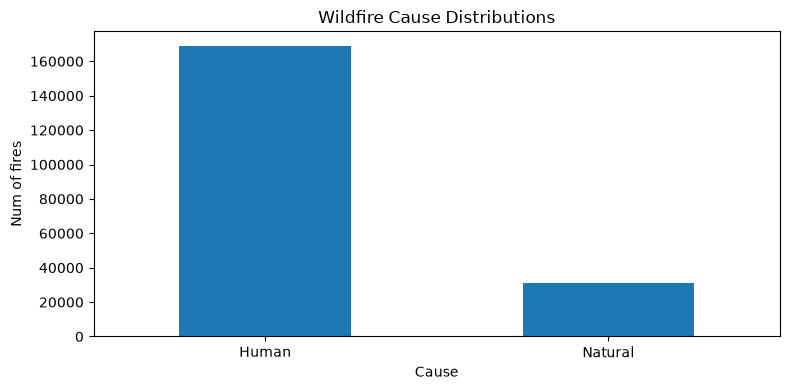

In [6]:
import matplotlib.pyplot as plt

#Fire Count
cause_counts = train_df["NWCG_CAUSE_CLASSIFICATION"].value_counts()

cause_counts.plot(kind = "bar", figsize = (8,4))

plt.title("Wildfire Cause Distributions")
plt.xlabel("Cause")
plt.ylabel("Num of fires")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

In [7]:

#features and target
features = [
    "FIRE_YEAR",
    "DISCOVERY_DOY",
    "LATITUDE",
    "LONGITUDE",
    "STATE"
]

target = "NWCG_CAUSE_CLASSIFICATION"


X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nTarget distribution:")
print(y_train.value_counts())

Training features: (200000, 5)
Validation features: (211022, 5)

Target distribution:
NWCG_CAUSE_CLASSIFICATION
Human      168978
Natural     31022
Name: count, dtype: int64


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "FIRE_YEAR",
    "DISCOVERY_DOY",
    "LATITUDE",
    "LONGITUDE"
]

categorical_features = ["STATE"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown = "ignore"), categorical_features)
])

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

#Logistic Regression 
log_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])
log_model.fit(X_train, y_train)
log_pred = log_model.predict(X_val)

# Evaluate performance
print("Logistic Regression")
print("Accuracy:", round(accuracy_score(y_val, log_pred), 4))
print("Macro F1:", round(f1_score(y_val, log_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_val, log_pred))


Logistic Regression
Accuracy: 0.8617
Macro F1: 0.6736

Classification Report:
              precision    recall  f1-score   support

       Human       0.89      0.96      0.92    178290
     Natural       0.60      0.33      0.43     32732

    accuracy                           0.86    211022
   macro avg       0.74      0.64      0.67    211022
weighted avg       0.84      0.86      0.84    211022



In [10]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest 
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
         n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_val)

# Evaluate performance
print("Random Forest")
print("Accuracy:", round(accuracy_score(y_val, rf_pred), 4))
print("Macro F1:", round(f1_score(y_val, rf_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_val, rf_pred))


Random Forest
Accuracy: 0.9273
Macro F1: 0.8517

Classification Report:
              precision    recall  f1-score   support

       Human       0.94      0.97      0.96    178290
     Natural       0.81      0.69      0.75     32732

    accuracy                           0.93    211022
   macro avg       0.88      0.83      0.85    211022
weighted avg       0.92      0.93      0.92    211022



In [11]:
from sklearn.svm import LinearSVC

# Linear SVM
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        max_iter=2000,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_val)

# Evaluate performance
print("Linear SVM")
print("Accuracy:", round(accuracy_score(y_val, svm_pred), 4))
print("Macro F1:", round(f1_score(y_val, svm_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_val, svm_pred))


Linear SVM
Accuracy: 0.8585
Macro F1: 0.6527

Classification Report:
              precision    recall  f1-score   support

       Human       0.88      0.96      0.92    178290
     Natural       0.59      0.29      0.39     32732

    accuracy                           0.86    211022
   macro avg       0.74      0.62      0.65    211022
weighted avg       0.84      0.86      0.84    211022



In [12]:
#traing and testing sets 
X_train_final = X_train
y_train_final = y_train

print("Training set:", X_train_final.shape)
print("Validation set:", X_val.shape)


Training set: (200000, 5)
Validation set: (211022, 5)


In [13]:
from sklearn.base import clone

#Logistic Regression Param Testing
for c in [0.01, 0.1, 1, 10]:
    for weight in [None, "balanced"]:
        model = clone(log_model)

        model.set_params(
            classifier__C = c,
            classifier__class_weight = weight
        )

        model.fit(X_train_final, y_train_final)
        predictions = model.predict(X_val)

        score = f1_score(y_val, predictions, average = "macro")

        print("C:", c, "Class Weight:", weight, "F1:", round(score, 4))

C: 0.01 Class Weight: None F1: 0.6553
C: 0.01 Class Weight: balanced F1: 0.6895
C: 0.1 Class Weight: None F1: 0.673
C: 0.1 Class Weight: balanced F1: 0.6906
C: 1 Class Weight: None F1: 0.6736
C: 1 Class Weight: balanced F1: 0.6901
C: 10 Class Weight: None F1: 0.6739
C: 10 Class Weight: balanced F1: 0.6906


In [ ]:
#Tuned Logistic Regression
log_tuned = clone(log_model)

log_tuned.set_params(
    classifier__C = 0.1,
    classifier__class_weight = "balanced"
)

log_tuned.fit(X_train_final, y_train_final)
log_tuned_pred = log_tuned.predict(X_val)

print("Tuned Logistic Regression")
print("Accuracy:", round(accuracy_score(y_val, log_tuned_pred), 4))
print("F1:", round(f1_score(y_val, log_tuned_pred, average = "macro"), 4))

print("\nClassification report:")
print(classification_report(y_val, log_tuned_pred))

Tuned Logistic Rgression
Accuracy: 0.7759
F1: 0.6906

Classification report:
              precision    recall  f1-score   support

       Human       0.96      0.77      0.85    178290
     Natural       0.39      0.81      0.53     32732

    accuracy                           0.78    211022
   macro avg       0.67      0.79      0.69    211022
weighted avg       0.87      0.78      0.80    211022



In [15]:
#Random Forest Testing(Depth)
for depth in [10, 15, 20, None]:
    model = clone(rf_model)
    model.set_params(classifier__max_depth = depth)

    model.fit(X_train_final, y_train_final)
    predictions = model.predict(X_val)

    score = f1_score(y_val, predictions, average = "macro")

    print("Max Depth:", depth, "F1:", round(score, 4))

Max Depth: 10 F1: 0.7679
Max Depth: 15 F1: 0.8179
Max Depth: 20 F1: 0.8371
Max Depth: None F1: 0.8517


In [16]:
#Random Forest Testing(Leaf)
for leaf in [1, 2, 5, 10]:
    model = clone(rf_model)
    model.set_params(
        classifier__max_depth = None,
        classifier__min_samples_leaf = leaf
    )

    model.fit(X_train_final, y_train_final)
    predictions = model.predict(X_val)

    score = f1_score(y_val, predictions, average = "macro")

    print("Min Leaf:", leaf, "F1:", round(score, 4))

Min Leaf: 1 F1: 0.855
Min Leaf: 2 F1: 0.8517
Min Leaf: 5 F1: 0.8422
Min Leaf: 10 F1: 0.8339


In [18]:
#Random Forest Testing(Trees)
for trees in [50, 100, 200, 300]:
    model = clone(rf_model)
    model.set_params(
        classifier__max_depth = None,
        classifier__min_samples_leaf = 1,
        classifier__n_estimators = trees
    )

    model.fit(X_train_final, y_train_final)
    predictions = model.predict(X_val)

    score = f1_score(y_val, predictions, average = "macro")

    print("Trees:", trees, "F1:", round(score, 4))

Trees: 50 F1: 0.8519
Trees: 100 F1: 0.8536
Trees: 200 F1: 0.855
Trees: 300 F1: 0.855


In [ ]:
for depth in [10, 15, 20, None]:
    for leaf in [1, 2, 5, 10]:
        for trees in [50, 100, 200, 300]:
            model = clone(rf_model)
            model.set_params(
                classifier__max_depth = depth,
                classifier__min_samples_leaf = leaf,
                classifier__n_estimators = trees
            )
        
            model.fit(X_train_final, y_train_final)
            predictions = model.predict(X_val)
        
            score = f1_score(y_val, predictions, average = "macro")
        
            print("Macro F1:", round(score, 4), "Max Depth:", depth, "Min Leaf:", leaf, "Trees:", trees)

Macro F1: 0.7611 Max Depth: 10 Min Leaf: 1 Trees: 50
Macro F1: 0.7672 Max Depth: 10 Min Leaf: 1 Trees: 100
Macro F1: 0.7701 Max Depth: 10 Min Leaf: 1 Trees: 200
Macro F1: 0.7714 Max Depth: 10 Min Leaf: 1 Trees: 300
Macro F1: 0.758 Max Depth: 10 Min Leaf: 2 Trees: 50
Macro F1: 0.7667 Max Depth: 10 Min Leaf: 2 Trees: 100
Macro F1: 0.7679 Max Depth: 10 Min Leaf: 2 Trees: 200
Macro F1: 0.7674 Max Depth: 10 Min Leaf: 2 Trees: 300
Macro F1: 0.7513 Max Depth: 10 Min Leaf: 5 Trees: 50
Macro F1: 0.7612 Max Depth: 10 Min Leaf: 5 Trees: 100
Macro F1: 0.7632 Max Depth: 10 Min Leaf: 5 Trees: 200
Macro F1: 0.7639 Max Depth: 10 Min Leaf: 5 Trees: 300
Macro F1: 0.7588 Max Depth: 10 Min Leaf: 10 Trees: 50
Macro F1: 0.7639 Max Depth: 10 Min Leaf: 10 Trees: 100
Macro F1: 0.7643 Max Depth: 10 Min Leaf: 10 Trees: 200
Macro F1: 0.7644 Max Depth: 10 Min Leaf: 10 Trees: 300
Macro F1: 0.8183 Max Depth: 15 Min Leaf: 1 Trees: 50
Macro F1: 0.8192 Max Depth: 15 Min Leaf: 1 Trees: 100
Macro F1: 0.8198 Max Depth: 15

In [19]:
#Tuned Random Forest 
rf_tuned = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
         n_estimators=200,
        max_depth=None,
        min_samples_leaf=1,
        random_state = 42,
        n_jobs = -1
    ))
])
rf_tuned.fit(X_train, y_train)
rf_tuned_pred = rf_tuned.predict(X_val)

print("Tuned Random Forest")
print("Accuracy:", round(accuracy_score(y_val, rf_tuned_pred), 4))
print("F1:", round(f1_score(y_val, rf_tuned_pred, average = "macro"), 4))

print("\nClassification report:")
print(classification_report(y_val, rf_tuned_pred))

Tuned Random Forest
Accuracy: 0.9283
F1: 0.855

Classification report:
              precision    recall  f1-score   support

       Human       0.95      0.97      0.96    178290
     Natural       0.81      0.70      0.75     32732

    accuracy                           0.93    211022
   macro avg       0.88      0.84      0.85    211022
weighted avg       0.93      0.93      0.93    211022



In [20]:
#SVM Param Testing
for c in [0.01, 0.1, 1, 10]:
    for weight in [None, "balanced"]:
        model = clone(svm_model)

        model.set_params(
            classifier__C = c,
            classifier__class_weight = weight
        )

        model.fit(X_train_final, y_train_final)
        predictions = model.predict(X_val)

        score = f1_score(y_val, predictions, average = "macro")

        print("C:", c, "Class Weight:", weight, "F1:", round(score, 4))

C: 0.01 Class Weight: None F1: 0.6509
C: 0.01 Class Weight: balanced F1: 0.69
C: 0.1 Class Weight: None F1: 0.6527
C: 0.1 Class Weight: balanced F1: 0.6907
C: 1 Class Weight: None F1: 0.6527
C: 1 Class Weight: balanced F1: 0.6908
C: 10 Class Weight: None F1: 0.6527
C: 10 Class Weight: balanced F1: 0.6908


In [21]:
#Tuned SVM
svm_tuned = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        C = 1,
        class_weight = "balanced",
        max_iter = 1000,
        random_state = 42
    ))
])

svm_tuned.fit(X_train, y_train)
svm_tuned_pred = svm_tuned.predict(X_val)

# Evaluate performance
print("Linear SVM")
print("Accuracy:", round(accuracy_score(y_val, svm_tuned_pred), 4))
print("Macro F1:", round(f1_score(y_val, svm_tuned_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_val, svm_tuned_pred))

Linear SVM
Accuracy: 0.7759
Macro F1: 0.6908

Classification Report:
              precision    recall  f1-score   support

       Human       0.96      0.77      0.85    178290
     Natural       0.39      0.81      0.53     32732

    accuracy                           0.78    211022
   macro avg       0.67      0.79      0.69    211022
weighted avg       0.87      0.78      0.80    211022



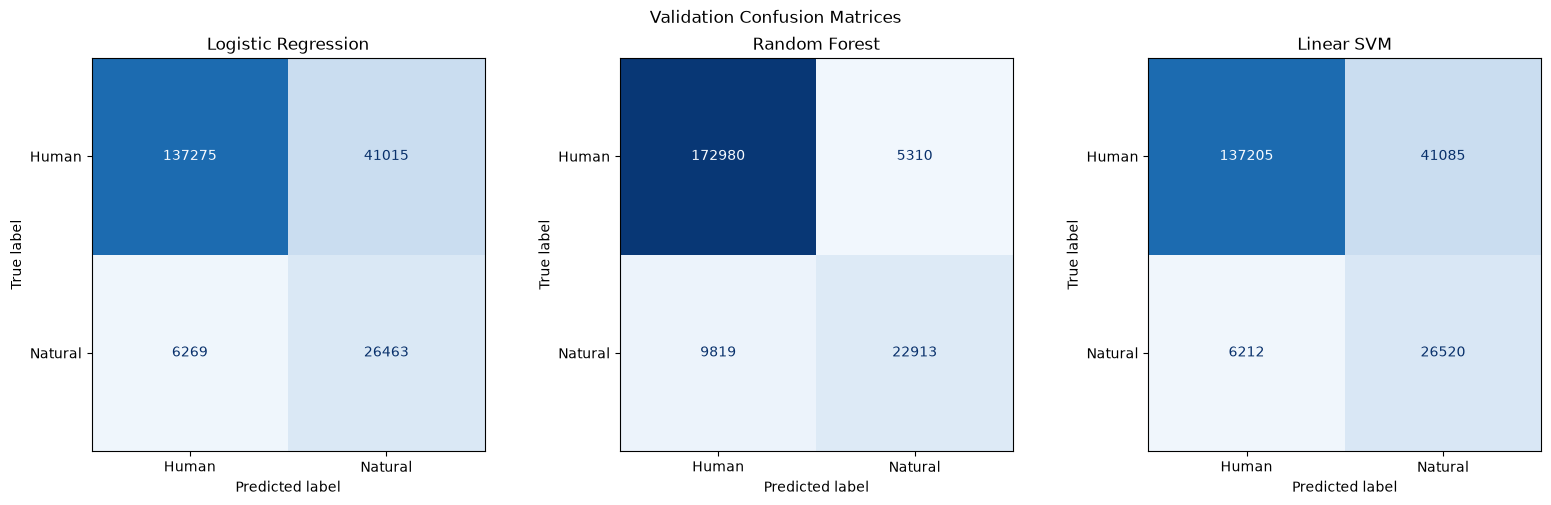

In [40]:
#Confusion Matrices
from sklearn.metrics import ConfusionMatrixDisplay

models = {
    "Logistic Regression": log_tuned,
    "Random Forest": rf_tuned,
    "Linear SVM": svm_tuned
    }


fig, axes = plt.subplots(1, 3, figsize = (16, 5))

for ax, (name, model) in zip(axes, models.items()):
    predicitions = model.predict(X_val)
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predicitions,
        labels = ["Human", "Natural"],
        cmap = "Blues",
        values_format = "d",
        ax = ax,
        colorbar=False
        )
    ax.images[0].set_clim(0, 178290)
    ax.set_title(name)

fig.suptitle("Validation Confusion Matrices")
plt.tight_layout()
plt.show()

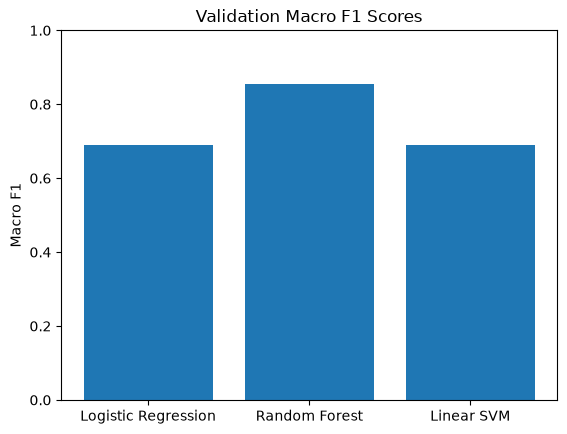

In [34]:
names = ["Logistic Regression", "Random Forest", "Linear SVM"]
val_f1_scores = [0.6906, 0.855, 0.6908]

plt.bar(names, val_f1_scores)
plt.title("Validation Macro F1 Scores")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.show()

In [23]:
X_test = test_df[features]
y_test = test_df[target]

print("Testing features:", X_test.shape)

print("\nTarget distribution:")
print(y_test.value_counts())

Testing features: (211023, 5)

Target distribution:
NWCG_CAUSE_CLASSIFICATION
Human      178291
Natural     32732
Name: count, dtype: int64


In [24]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy = "most_frequent")
dummy_model.fit(X_train, y_train)
dummy_pred = dummy_model.predict(X_test)

print("Most Frequent Classifier")
print("Accuracy:", round(accuracy_score(y_test, dummy_pred), 4))
print("Macro F1:", round(f1_score(y_test, dummy_pred, average = "macro"), 4))

Most Frequent Classifier
Accuracy: 0.8449
Macro F1: 0.458


In [25]:
for name, model in models.items():
    test_pred = model.predict(X_test)
    print("\n", name)
    print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
    print("Macro F1:", round(f1_score(y_test, test_pred, average = "macro"), 4))


 Logistic Regression
Accuracy: 0.7771
Macro F1: 0.6919

 Random Forest
Accuracy: 0.9288
Macro F1: 0.8555

 Linear SVM
Accuracy: 0.7769
Macro F1: 0.692


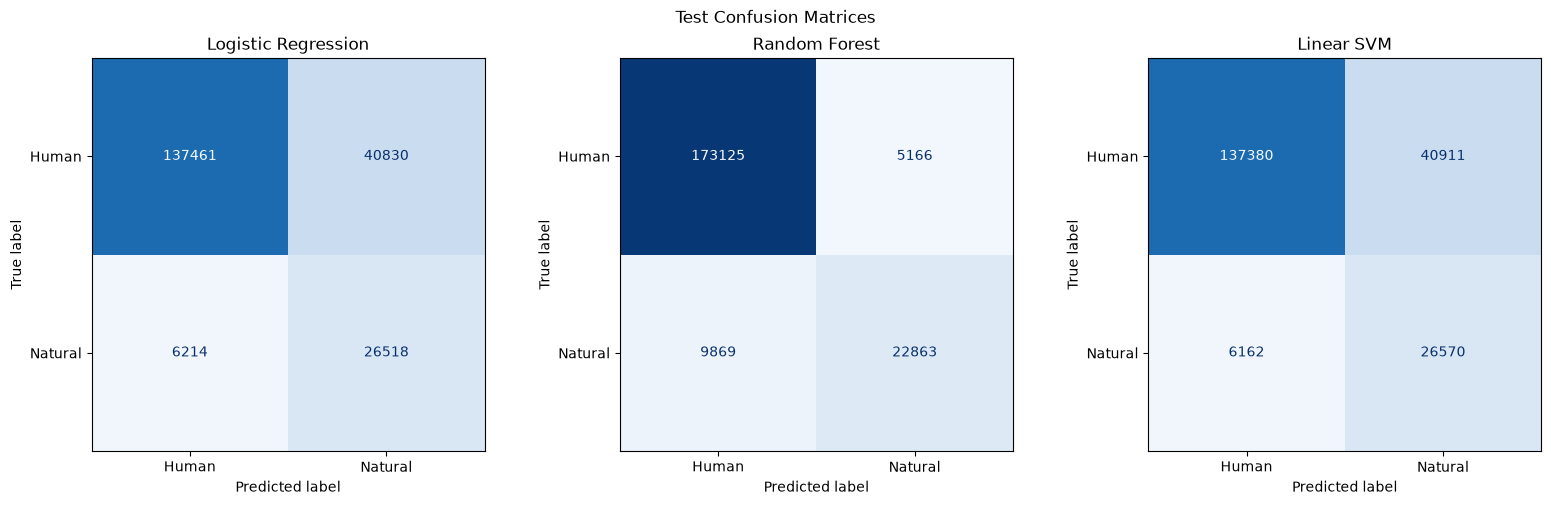

In [41]:
fig, axes = plt.subplots(1, 3, figsize = (16, 5))

for ax, (name, model) in zip(axes, models.items()):
    test_pred = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_pred,
        labels = ["Human", "Natural"],
        cmap = "Blues",
        values_format = "d",
        ax = ax,
        colorbar=False
        )
    ax.images[0].set_clim(0, y_test.value_counts().max())
    ax.set_title(name)

fig.suptitle("Test Confusion Matrices")
plt.tight_layout()
plt.show()

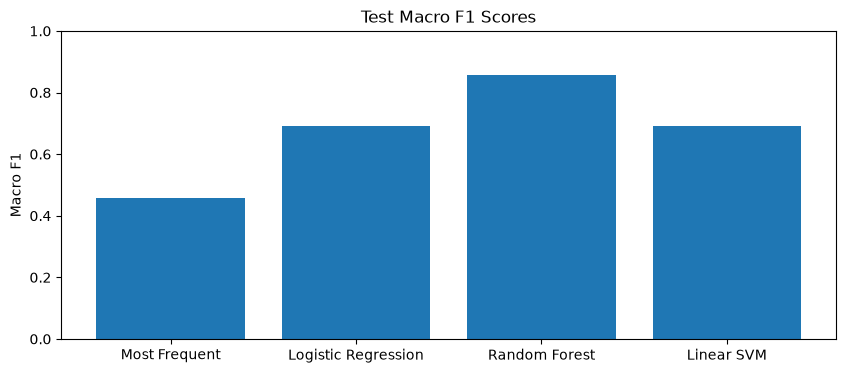

In [35]:
names.insert(0, "Most Frequent")
test_f1_scores = [0.458, 0.6919, 0.8555, 0.692]

plt.figure(figsize= (10, 4))
plt.bar(names, test_f1_scores)
plt.title("Test Macro F1 Scores")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.show()

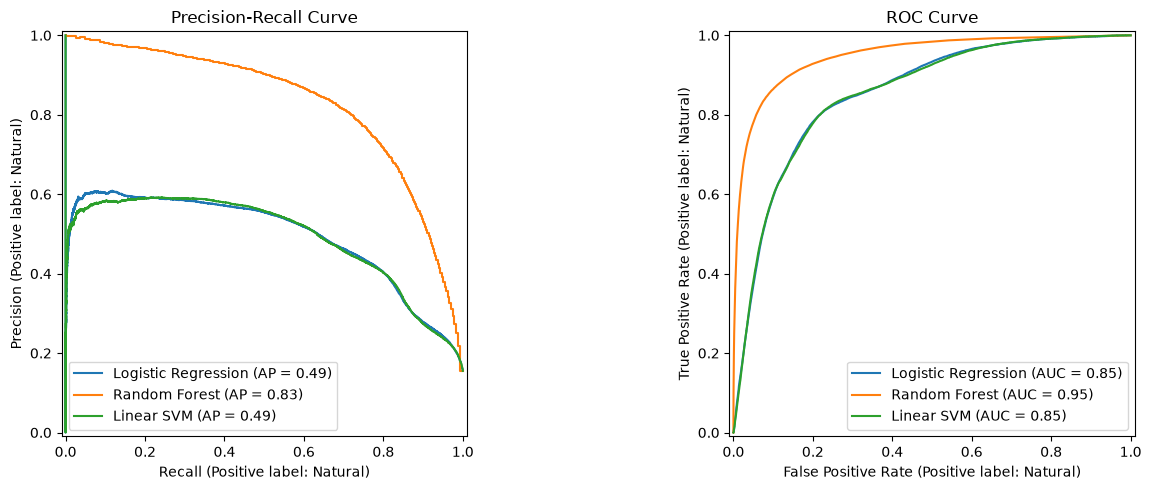

In [28]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

fig, (a1, a2) = plt.subplots(1, 2, figsize = (14, 5))

for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name = name, ax = a1)
    RocCurveDisplay.from_estimator(model, X_test, y_test, name = name, ax = a2)

a1.set_title("Precision-Recall Curve")
a2.set_title("ROC Curve")

plt.tight_layout()
plt.show()